In [18]:
import os
import warnings
import joblib

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import rasterio
from rasterio.mask import mask
from rasterio.features import geometry_mask
from rasterio.plot import show

from sklearn.ensemble import RandomForestClassifier
from coral import coral_fit,coral_apply

warnings.filterwarnings("ignore")

np.random.seed(42)

In [65]:
# -----------------------------
# KRISHNA DATA
# -----------------------------

KRISHNA_IMAGE = r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\krishsatemb2024.tif"

KRISHNA_AOI = r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\krishna_east_div\krishna_east_div.shp"

KRISHNA_GT = r"C:\Users\snvra\NISAR_Data_project\Data\krishna_gt\train_2024.shp"

# -----------------------------
# MALAD DATA
# -----------------------------

MALAD_IMAGE = r"Malad_Mosaic.tif"

MALAD_AOI = r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\Malad_mang\malad_mang_mask.shp"

MALAD_GT = r"C:\Users\snvra\NISAR_Data_project\Data\malad_gt\malad_gt.shp"

# -----------------------------
# OUTPUT
# -----------------------------

OUTPUT_FOLDER = r"C:\Users\snvra\NISAR_Data_project\classifier models"

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

In [66]:
# Krishna GT
krishna_gt = gpd.read_file(KRISHNA_GT)

# Krishna AOI
krishna_aoi=gpd.read_file(KRISHNA_AOI)

# Malad AOI
malad_aoi = gpd.read_file(MALAD_AOI)

# Krishna raster
krishna_src = rasterio.open(KRISHNA_IMAGE)

# Malad raster
malad_src = rasterio.open(MALAD_IMAGE)

In [67]:
# Crop Krishna raster to AOI
krishna_clip, krishna_transform = mask(
    krishna_src,
    krishna_aoi.geometry,
    crop=True,
    filled=True,
    nodata=np.nan
)

# Convert to (rows, cols, bands)
krishna_clip = np.moveaxis(
    krishna_clip,
    0,
    -1
)

print("Krishna AOI Shape :", krishna_clip.shape)

Krishna AOI Shape : (2069, 1919, 64)


In [68]:
# Valid pixels

krishna_valid = np.all(
    np.isfinite(krishna_clip),
    axis=2
)

# Reference feature matrix

X_reference = krishna_clip[krishna_valid]

print("Reference Features :", X_reference.shape)

print()

print("Any NaN :", np.isnan(X_reference).any())
print("Any Inf :", np.isinf(X_reference).any())

print()

print("Minimum :", X_reference.min())
print("Maximum :", X_reference.max())

Reference Features : (1846701, 64)

Any NaN : False
Any Inf : False

Minimum : -0.4982698961937717
Maximum : 0.4982698961937717


In [69]:
malad_clip, malad_transform = mask(
    malad_src,
    malad_aoi.geometry,
    crop=True,
    filled=True,
    nodata=np.nan
)

malad_clip = np.moveaxis(
    malad_clip,
    0,
    -1
)

rows, cols, bands = malad_clip.shape

valid_mask = np.all(
    np.isfinite(malad_clip),
    axis=2
)

X_target = malad_clip[valid_mask]

print(X_target.shape)

(77014, 64)


In [70]:
params = coral_fit(
    X_target,
    X_reference   # we'll create this below
)

aligned_pixels = coral_apply(
    X_target,
    params
)

print(aligned_pixels.shape)

(77014, 64)


In [ ]:
def extract_binary_training(
    raster,
    gt,
    transform,
    target_species
):

    y = []

    for _, row in gt.iterrows():

        mask_geom = geometry_mask(
            [row.geometry],
            transform=transform,
            invert=True,
            out_shape=(
                raster.shape[0],
                raster.shape[1]
            )
        )

        pixels = raster[mask_geom]

        pixels = pixels[
            np.all(
                np.isfinite(pixels),
                axis=1
            )
        ]

        if len(pixels) == 0:
            continue

        label = 1 if row["label"] == target_species else 0

        X.append(pixels)

        y.extend(
            [label]*len(pixels)
        )

    X = np.vstack(X)

    y = np.array(y)

    return X, y

In [134]:
species_list = [
    "A_marina_dense",
    "Rhizophora_sp",
    "Creek_Waterbody"
]

species_short = {
    "A_marina_dense": "Dense",
    "Rhizophora_sp": "Rhizophora",
    "Creek_Waterbody": "Waterbody",
}

MODEL_FOLDER = os.path.join(OUTPUT_FOLDER, "Models")
MAP_FOLDER = os.path.join(OUTPUT_FOLDER, "Probability_Maps")

os.makedirs(MODEL_FOLDER, exist_ok=True)
os.makedirs(MAP_FOLDER, exist_ok=True)

for species in species_list:

    print("="*70)
    print("Training :", species)

    # ---------------------------------------------------
    # Extract Binary Training Data
    # ---------------------------------------------------

    X_train, y_train = extract_binary_training(
        raster=krishna_image,
        gt=krishna_gt,
        transform=krishna_src.transform,
        target_species=species
    )

    print("Training Samples")
    print(np.unique(y_train, return_counts=True))

    # ---------------------------------------------------
    # Train RF
    # ---------------------------------------------------

    rf = RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    print("Training Accuracy :",
          rf.score(X_train, y_train))

    # ---------------------------------------------------
    # Save Model
    # ---------------------------------------------------

    model_path = os.path.join(
        MODEL_FOLDER,
        species_short[species] + "_RF.pkl"
    )

    joblib.dump(rf, model_path)

    print("Model Saved :", model_path)

    # ---------------------------------------------------
    # Predict Probability
    # ---------------------------------------------------

    probability = rf.predict_proba(
        aligned_pixels
    )[:,1]

    # ---------------------------------------------------
    # Create Probability Map
    # ---------------------------------------------------

    probability_map = np.full(
     (rows, cols),
     np.nan,
     dtype=np.float32
    )

    probability_map[valid_mask] = probability

    probability_map = probability_map.reshape(
        rows,
        cols
    )

    # ---------------------------------------------------
    # Save GeoTIFF
    # ---------------------------------------------------

    tif_path = os.path.join(
        MAP_FOLDER,
        species_short[species] + "_Probability.tif"
    )

    with rasterio.open(
        tif_path,
        "w",
        driver="GTiff",
        height=rows,
        width=cols,
        count=1,
        dtype="float32",
        crs=malad_src.crs,
        transform=malad_transform,
        nodata=np.nan
    ) as dst:

        dst.write(probability_map, 1)

    print("Probability Map Saved :", tif_path)

print("\nAll Species Models Trained Successfully.")

Training : A_marina_dense
Training Samples
(array([0, 1]), array([14583,  2115]))
Training Accuracy : 1.0
Model Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Models\Dense_RF.pkl
Probability Map Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Dense_Probability.tif
Training : Rhizophora_sp
Training Samples
(array([0, 1]), array([16153,   545]))
Training Accuracy : 1.0
Model Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Models\Rhizophora_RF.pkl
Probability Map Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Rhizophora_Probability.tif
Training : Creek_Waterbody
Training Samples
(array([0, 1]), array([15139,  1559]))
Training Accuracy : 1.0
Model Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Models\Waterbody_RF.pkl
Probability Map Saved : C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Waterbody_Probability.tif

All Species Models Trained Successfully.


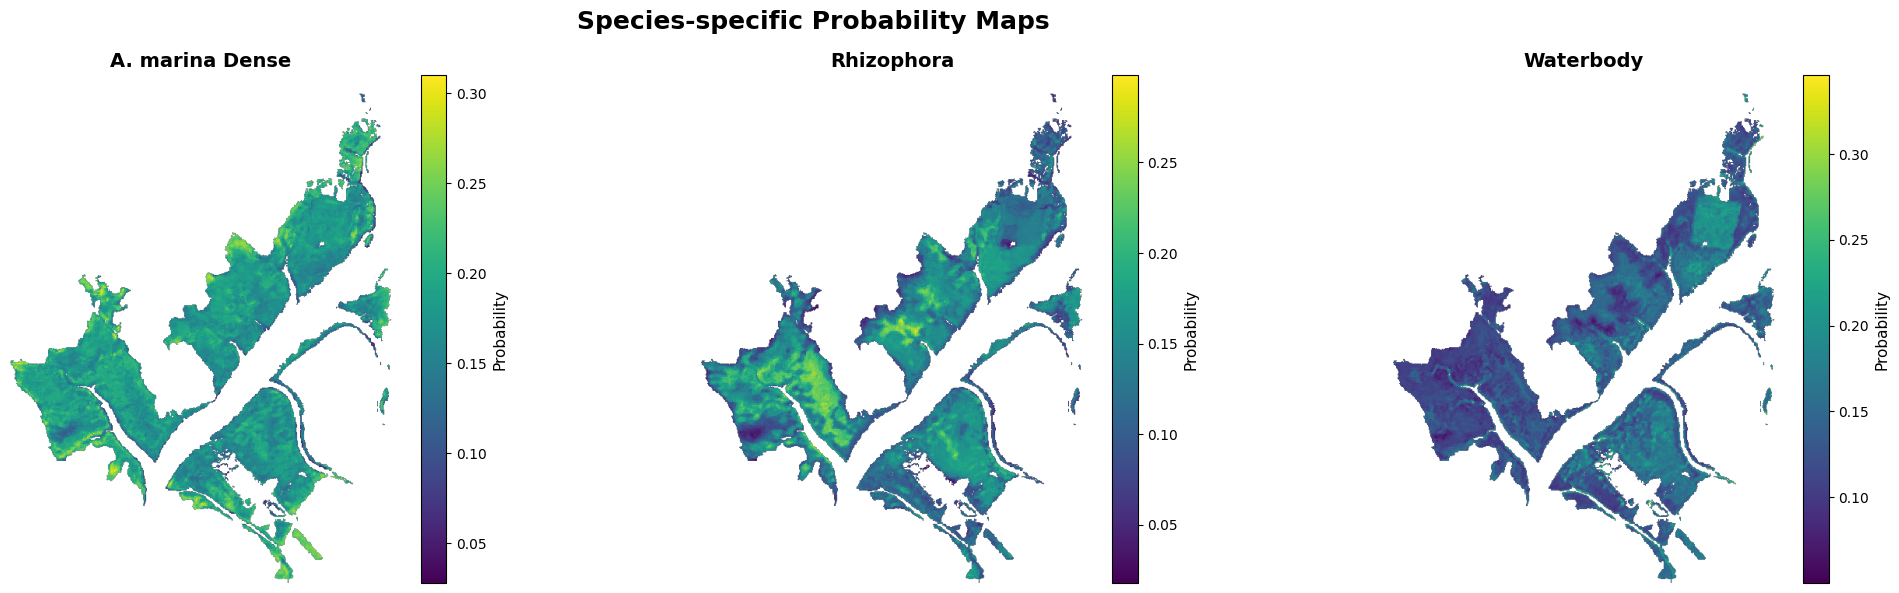

In [203]:
import rasterio
import matplotlib.pyplot as plt
import os

maps = [
    (r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Dense_Probability.tif", "A. marina Dense"),
    (r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Rhizophora_Probability.tif", "Rhizophora sp."),
    (r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Waterbody_Probability.tif", "Creek_Waterbody"),
]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

maps = [
    (dense_map, "A. marina Dense"),
    (rhizophora_map, "Rhizophora"),
    (waterbody_map, "Waterbody"),
]

for ax, (img, title) in zip(axes, maps):

    valid = img[np.isfinite(img)]

    vmin = valid.min()
    vmax = valid.max()

    im = ax.imshow(
        img,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

    cbar = plt.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label("Probability", fontsize=11)

plt.suptitle(
    "Species-specific Probability Maps",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Species_specific_probability_Maps.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [136]:
import rasterio
import pandas as pd
import seaborn as sns
from rasterio.features import geometry_mask

probability_maps = {
    "Dense": rasterio.open(
        os.path.join(MAP_FOLDER, r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Dense_Probability.tif")
    ).read(1),

    "Rhizophora": rasterio.open(
        os.path.join(MAP_FOLDER, r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Rhizophora_Probability.tif")
    ).read(1),

    "Waterbody": rasterio.open(
        os.path.join(MAP_FOLDER, r"C:\Users\snvra\NISAR_Data_project\classifier models\Probability_Maps\Waterbody_Probability.tif")
    ).read(1),

}

In [147]:
malad_gt = gpd.read_file(MALAD_GT)
# Remove Moderate polygon
malad_gt_eval = malad_gt[malad_gt["label"] != "am02"].copy()

print(malad_gt_eval["label"].value_counts())


label
rh      1
am01    1
Name: count, dtype: int64


In [148]:
results = []

for _, row in malad_gt_eval.iterrows():

    mask_geom = geometry_mask(
        [row.geometry],
        transform=malad_transform,
        invert=True,
        out_shape=(rows, cols)
    )

    record = {
        "GT": row["label"]
    }

    for model_name, prob in probability_maps.items():

        values = prob[mask_geom]

        values = values[np.isfinite(values)]

        record[model_name] = np.mean(values)

    results.append(record)

In [149]:
matrix = (
    pd.DataFrame(results)
      .groupby("GT")
      .mean()
)

matrix

,Dense,Rhizophora,Waterbody
GT,,,
am01,0.179536,0.157043,0.163024
rh,0.180870,0.191087,0.098217


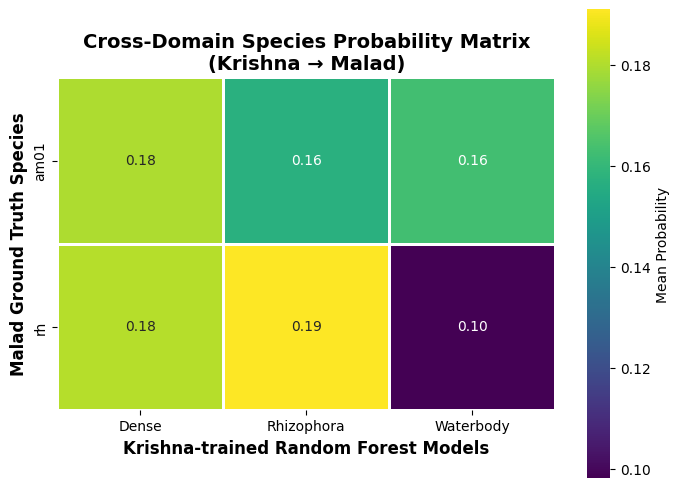

In [202]:
plt.figure(figsize=(7,5))

ax = sns.heatmap(
    matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=1,
    square=True,
    cbar_kws={
        "label":"Mean Probability"
    }
)

ax.set_xlabel(
    "Krishna-trained Random Forest Models",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Malad Ground Truth Species",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Cross-Domain Species Probability Matrix\n(Krishna → Malad)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Cross_domain_probability_matrix.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [151]:
dense_map = probability_maps["Dense"]
rhizophora_map = probability_maps["Rhizophora"]
waterbody_map = probability_maps["Waterbody"]

In [178]:
# 0 = Dense
# 1 = Rhizophora

prob_stack = np.stack([
    dense_map,
    rhizophora_map
], axis=0)

species_map = np.argmax(prob_stack, axis=0).astype(np.uint8)

# Water mask
species_map[waterbody_map > 0.30] = 2

# Outside AOI
species_map[~valid_mask] = 255

In [179]:
species_no_water = species_map.copy()

# Ignore water and NoData
species_no_water[(species_no_water == 2) | (species_no_water == 255)] = 0

agreement = (
    species_map[valid_mask] ==
    np.argmax(
        np.stack([dense_map, rhizophora_map]),
        axis=0
    )[valid_mask]
)

print(agreement.mean())

0.9997922455657413


In [180]:
winner = np.argmax(
    np.stack([dense_map, rhizophora_map]),
    axis=0
)

rh_wins = np.sum(winner == 1)
dense_wins = np.sum(winner == 0)

print("Dense wins :", dense_wins)
print("Rhizophora wins :", rh_wins)

Dense wins : 306786
Rhizophora wins : 13837


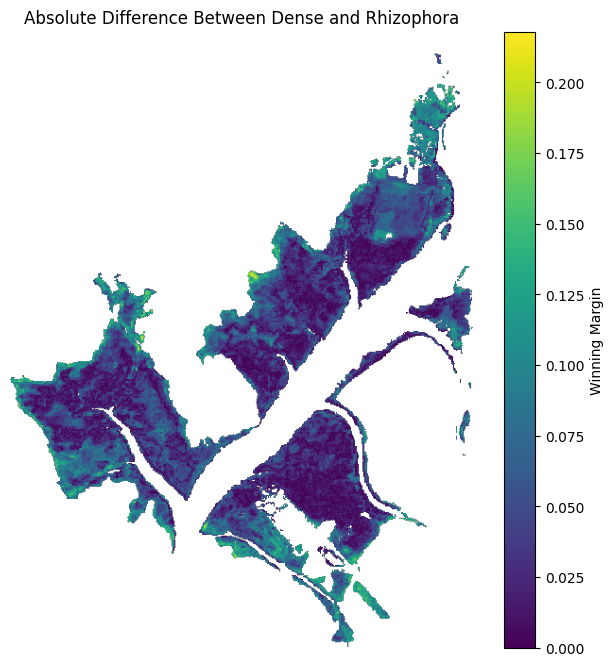

In [201]:
margin = np.abs(dense_map - rhizophora_map)

plt.figure(figsize=(8,8))
plt.imshow(margin, cmap="viridis")
plt.colorbar(label="Winning Margin")
plt.title("Absolute Difference Between Dense and Rhizophora")
plt.axis("off")

plt.savefig(
    "Absolute_difference_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

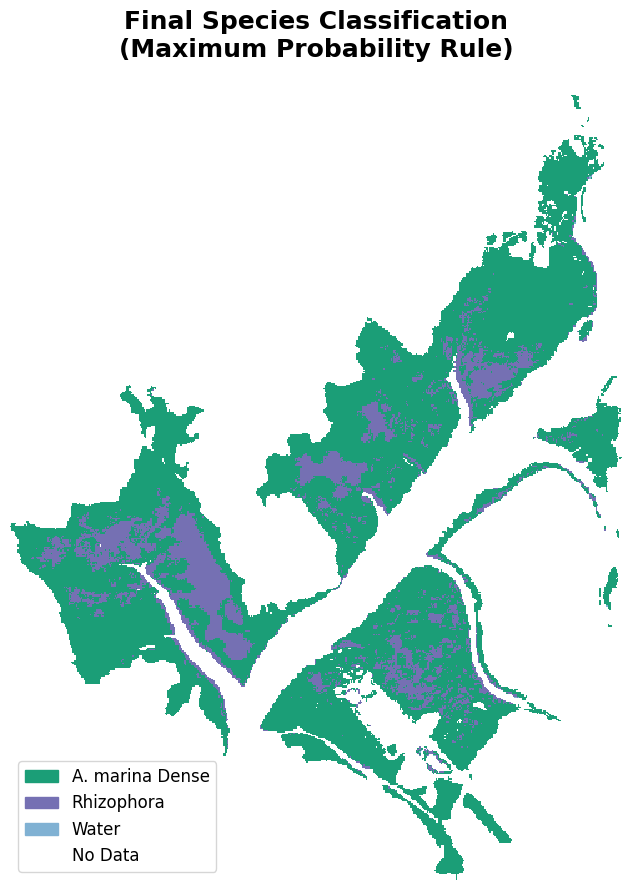

In [198]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# -------------------------------------------------------
# Stack only Dense and Rhizophora
# -------------------------------------------------------

prob_stack = np.stack([
    dense_map,
    rhizophora_map
], axis=0)

# 0 = Dense
# 1 = Rhizophora
species_map = np.argmax(prob_stack, axis=0).astype(np.uint8)

# -------------------------------------------------------
# Apply Water Mask
# -------------------------------------------------------

water_threshold = 0.30      # Change if required

species_map[waterbody_map > water_threshold] = 2

# -------------------------------------------------------
# Outside AOI
# -------------------------------------------------------

species_map[~valid_mask] = 255

# -------------------------------------------------------
# Plot
# -------------------------------------------------------

colors = [
    "#1b9e77",   # Dense
    "#7570b3",   # Rhizophora
    "#80b1d3",   # Water
    "#ffffff"    # NoData
]

cmap = ListedColormap(colors)

plot_map = species_map.copy()

# Replace NoData (255) with index 3 for plotting
plot_map[plot_map == 255] = 3

plt.figure(figsize=(9,9))

plt.imshow(
    plot_map,
    cmap=cmap,
    interpolation="nearest"
)

from matplotlib.patches import Patch

legend = [
    Patch(color="#1b9e77", label="A. marina Dense"),
    Patch(color="#7570b3", label="Rhizophora"),
    Patch(color="#80b1d3", label="Water"),
    Patch(color="#ffffff", label="No Data")
]

plt.legend(
    handles=legend,
    loc="lower left",
    fontsize=12,
    frameon=True
)

plt.title(
    "Final Species Classification\n(Maximum Probability Rule)",
    fontsize=18,
    fontweight="bold"
)

plt.axis("off")

plt.tight_layout()

plt.savefig(
    "Final_Species_Classification.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



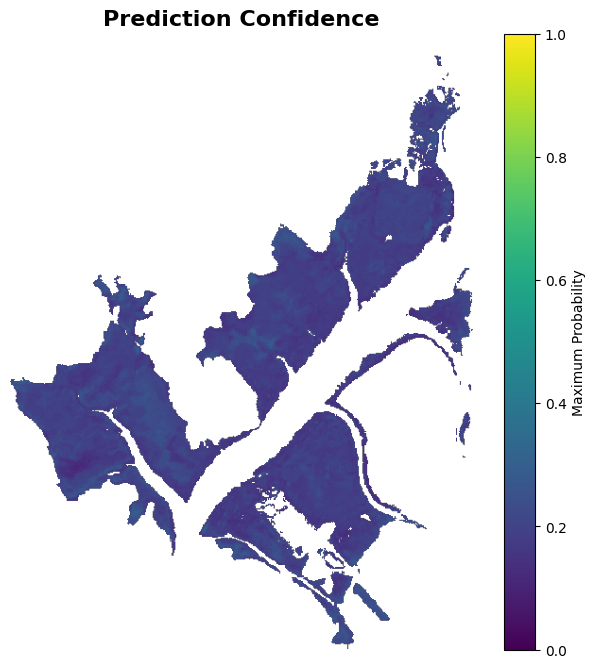

In [199]:
plt.figure(figsize=(8,8))

plt.imshow(
    maximum_probability,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Maximum Probability")

plt.title(
    "Prediction Confidence",
    fontsize=16,
    fontweight="bold"
)

plt.axis("off")

plt.savefig(
    "Prediction_confidence.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [160]:
maps = {
    "Dense": dense_map,
    "Rhizophora": rhizophora_map,
    "Water": waterbody_map
}

for name, img in maps.items():

    vals = img[np.isfinite(img)]

    print("="*50)
    print(name)

    print("Mean :", vals.mean())
    print("Median :", np.median(vals))
    print("Max :", vals.max())

    print("95th :", np.percentile(vals,95))
    print("99th :", np.percentile(vals,99))

Dense
Mean : 0.1817118
Median : 0.18
Max : 0.31
95th : 0.234
99th : 0.26
Rhizophora
Mean : 0.14294256
Median : 0.144
Max : 0.298
95th : 0.218
99th : 0.24
Water
Mean : 0.13979958
Median : 0.134
Max : 0.346
95th : 0.198
99th : 0.22


In [163]:
print(malad_gt_eval.columns)

print(malad_gt_eval["label"].value_counts())

Index(['label', 'value', 'geometry'], dtype='object')
label
rh      1
am01    1
Name: count, dtype: int64


In [164]:
labels = {
    0: "Dense",
    1: "Rhizophora",
    2: "Water",
    255: "NoData"
}

unique, counts = np.unique(species_map, return_counts=True)

for u, c in zip(unique, counts):
    print(f"{labels.get(u, u):12s}: {c}")

Dense       : 53187
Rhizophora  : 10669
Water       : 13158
NoData      : 243609


In [165]:
from rasterio.features import geometry_mask

# Only the two classes to be evaluated as moderate species are outnumbered 
label_map = {
    "am01": 0,   # Dense
    "rh":   1    # Rhizophora
}

y_true = []
y_pred = []

for _, row in malad_gt_eval.iterrows():

    # Skip Moderate polygon
    if row["label"] == "am02":
        continue

    gt_label = label_map[row["label"]]

    mask_geom = geometry_mask(
        [row.geometry],
        transform=malad_transform,
        invert=True,
        out_shape=(rows, cols)
    )

    pred = species_map[mask_geom]

    # Remove Water and NoData
    pred = pred[(pred != 2) & (pred != 255)]

    # Remove any unexpected labels
    pred = pred[np.isin(pred, [0, 1])]

    if len(pred) == 0:
        continue

    y_true.extend([gt_label] * len(pred))
    y_pred.extend(pred)

In [166]:
print("Evaluation Pixels :", len(y_true))

print("Ground Truth")
print(np.unique(y_true, return_counts=True))

print("Prediction")
print(np.unique(y_pred, return_counts=True))

Evaluation Pixels : 189
Ground Truth
(array([0, 1]), array([143,  46]))
Prediction
(array([0, 1], dtype=uint8), array([165,  24]))


In [167]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0,1]
)

oa = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

kappa = cohen_kappa_score(
    y_true,
    y_pred
)

In [186]:
classes = [
    "Dense",
    "Rhizophora"
]

print("="*50)
print("Overall Accuracy :", oa)
print("Kappa :", kappa)

print("\nPer-Class Metrics")

for i, cls in enumerate(classes):

    print(f"\n{cls}")

    print("Precision :", precision[i])

    print("Recall    :", recall[i])

    print("F1-score  :", f1[i])

Overall Accuracy : 0.8624338624338624
Kappa : 0.5541643984757757

Per-Class Metrics

Dense
Precision : 0.8545454545454545
Recall    : 0.986013986013986
F1-score  : 0.9155844155844156

Rhizophora
Precision : 0.9166666666666666
Recall    : 0.4782608695652174
F1-score  : 0.6285714285714286


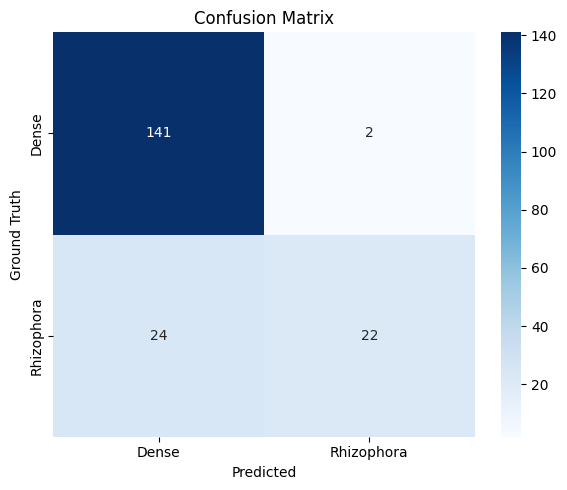

In [187]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Ground Truth")

plt.title("Confusion Matrix")

plt.tight_layout()

plt.show()

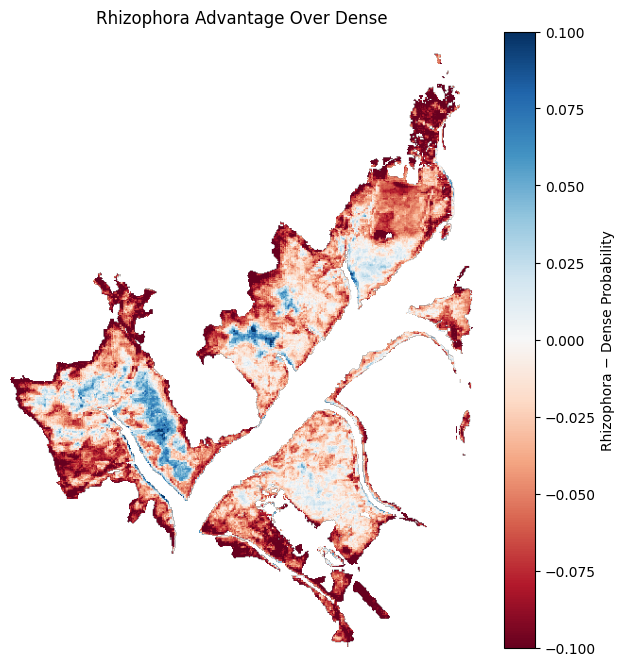

In [200]:
difference = rhizophora_map - dense_map

plt.figure(figsize=(8, 8))
plt.imshow(difference, cmap="RdBu", vmin=-0.1, vmax=0.1)
plt.colorbar(label="Rhizophora − Dense Probability")
plt.title("Rhizophora Advantage Over Dense")
plt.axis("off")

plt.savefig(
    "Rhizophora_Advantage.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()